In [1]:
import yaml
import warnings
import sys

import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as pl
import seaborn as sns
import PyComplexHeatmap as pch
from pathlib import Path
from tqdm.auto import tqdm

# make figures paper quality
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
matplotlib.rcParams['font.family'] = 'sans-serif'
matplotlib.rcParams['font.sans-serif'] = 'Arial'

# Remove warning, we like to live dangerously
warnings.filterwarnings("ignore")

# load functions from ../utils
sys.path.append('../utils')
from utils import get_nnmd

# Get config settings
with open('../configuration/config.yaml', "r") as file:
    config = yaml.load(file, Loader=yaml.FullLoader)
cell_line_dict=config['cell_lines']

In [2]:
# counts
df = pd.read_csv(Path(config['TEMPDIR']) / 'pooled_screen_1/pooled_screen_1_counts.csv', index_col=0)
# essential genes
essential = pd.read_csv("../resources/bagel_supplement/CEGv2.txt", sep='\t', index_col=0)
non_essential = pd.read_csv("../resources/bagel_supplement/NEGv1.txt", sep='\t', index_col=0)

# Gscreend Fernanda (gene-wise)

In [2]:
tabs = {}
for i in [1,2,3]:
    tabs[cell_line_dict[i]] = pd.read_excel(f'../resources/fernanda_gscreend/gscreend_results_Sym101_0{i}.xlsx')

In [3]:
tabs['H1975']

,Gene,FDR_TP1,pvalue_TP1,LFC_TP1,Diffexpress_TP1,FDR_TP2,pvalue_TP2,LFC_TP2,Diffexpress_TP2,FDR_TP3,...,LFC_TP4,Diffexpress_TP4,FDR_TP5,pvalue_TP5,LFC_TP5,Diffexpress_TP5,FDR_TP6,pvalue_TP6,LFC_TP6,Diffexpress_TP6
0,AATBC,1.0,1.000000,0.089637,NO,1.0,1.000000,0.128774,NO,1.000000,...,0.188654,NO,1.0,1.000000,0.187648,NO,1.000000,1.000000,0.224566,NO
1,ACKR2,1.0,0.845879,0.007570,NO,1.0,0.936649,0.003993,NO,1.000000,...,0.068886,NO,1.0,1.000000,0.125832,NO,1.000000,1.000000,0.110799,NO
2,ACTA2-AS1,1.0,1.000000,0.094964,NO,1.0,1.000000,0.145627,NO,1.000000,...,0.269447,NO,1.0,1.000000,0.281698,NO,1.000000,1.000000,0.308602,NO
3,ACTB,0.0,0.000000,-0.589395,DOWN,0.0,0.000000,-1.005634,DOWN,0.000000,...,-1.655178,DOWN,0.0,0.000000,-1.733700,DOWN,0.000000,0.000000,-1.921871,DOWN
4,ACTG1,0.0,0.000000,-0.845664,DOWN,0.0,0.000000,-1.334491,DOWN,0.000000,...,-2.163782,DOWN,0.0,0.000000,-2.404333,DOWN,0.000000,0.000000,-2.751955,DOWN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
729,ZNF728,1.0,1.000000,-0.049971,NO,1.0,1.000000,0.012667,NO,1.000000,...,0.109417,NO,1.0,1.000000,0.112433,NO,1.000000,1.000000,0.159111,NO
730,ZNF93,1.0,1.000000,-0.001196,NO,1.0,0.943290,-0.050000,NO,1.000000,...,-0.286134,NO,1.0,0.537296,-0.384417,NO,1.000000,0.472071,-0.450325,NO
731,ZNHIT2,1.0,1.000000,-0.317678,NO,1.0,1.000000,-0.258504,NO,1.000000,...,-0.154158,NO,1.0,1.000000,-0.158300,NO,1.000000,1.000000,-0.104442,NO
732,ZRANB2,0.0,0.000000,-0.430054,DOWN,0.0,0.000000,-0.403624,DOWN,0.058824,...,-0.508717,NO,1.0,0.286444,-0.593669,NO,0.704605,0.182391,-0.682940,NO


In [5]:
for cell_line in cell_line_dict.values():

    groups = ['DOWN', 'NO', 'UP']

    tab = tabs[cell_line]
    source = []
    target = []
    label = groups.copy()
    value = []
    pos = []
    for layer in [1,2,3,4,5]:
        for i, xi in enumerate(groups):
            label.append(xi)
            pos.append(layer)
            for j, xj in enumerate(groups):
                source.append(i + 3 * layer)
                target.append(j + 3 * (layer + 1))
                # transition
                v = ((tab[f'Diffexpress_TP{layer}'] == xi) & (tab[f'Diffexpress_TP{layer+1}'] == xj)).sum()
                value.append(v)
    label.extend(groups)
    pos.extend([6, 6, 6])
    color = ['blue' if x == 'UP' else 'red' if x == 'DOWN' else 'gray' for x in label]

    label = [x.replace('NO', 'Not significant') for x in label]
    
    import plotly.graph_objects as go

    link = dict(source = source, target = target, value = value)
    data = go.Sankey(link = link, node = dict(
        x = pos,
        pad = 15,
        thickness = 20,
        line = dict(color = "black", width = 0.5),
        label = label,
        color = color
        ),)

    fig = go.Figure(data)
    fig.update_layout(
        autosize=False,
        width=800,
        height=300,
    )
    fig.show()

## Compare with BAGEL2 results

In [21]:
file = '../results/tables/pooled_screen_1_bagel_pr_gene.tsv'
df = pd.read_table(file, index_col=0, header=[0,1,2])

In [22]:
df

alllines                                                     \
            alltimes                            TP5TP6                    
                  BF Recall Precision    FDR        BF Recall Precision   
Gene                                                                      
RAN         9969.672  0.005     1.000  0.000  5798.778  0.005     1.000   
FBL         5449.419  0.005     1.000  0.000  3394.553  0.005     1.000   
EIF4A1      4661.117  0.005     1.000  0.000  2410.584  0.010     1.000   
HNRNPA1     4135.492  0.005     1.000  0.000  2185.951  0.010     1.000   
SNHG16      3811.712  0.005     1.000  0.000  2233.446  0.010     1.000   
...              ...    ...       ...    ...       ...    ...       ...   
PCAT1      -1172.589  1.000     0.865  0.135  -553.261  1.000     0.865   
PCBP4      -1203.189  1.000     0.865  0.135  -600.722  1.000     0.865   
BIN1       -1436.490  1.000     0.865  0.135  -639.859  1.000     0.865   
HOTAIRM1   -1581.295  1.000     0.865  0.135  -800.927  1.000     0.865   
NT_Control -2505.494  1.000     0.865  0.135 -1424.679  1.000     0.865   

                       A549         ...     H1299            H1975         \
                   alltimes         ...    TP5TP6         alltimes          
              FDR        BF Recall  ... Precision    FDR        BF Recall   
Gene                                ...                                     
RAN         0.000  2046.360  0.005  ...     1.000  0.000  3094.169  0.005   
FBL         0.000   586.054  0.065  ...     1.000  0.000  2575.971  0.005   
EIF4A1      0.000  1225.385  0.005  ...     1.000  0.000  1279.115  0.005   
HNRNPA1     0.000  1146.395  0.005  ...     1.000  0.000   890.383  0.020   
SNHG16      0.000  1001.866  0.015  ...     1.000  0.000   906.484  0.020   
...           ...       ...    ...  ...       ...    ...       ...    ...   
PCAT1       0.135  -340.449  1.000  ...     0.865  0.135  -447.549  1.000   
PCBP4       0.135  -368.308  1.000  ...     0.865  0.135  -479.808  1.000   
BIN1        0.135  -344.503  1.000  ...     0.865  0.135  -618.303  1.000   
HOTAIRM1    0.135  -474.106  1.000  ...     0.865  0.135  -605.877  1.000   
NT_Control  0.135  -516.507  1.000  ...     0.865  0.135 -1100.500  1.000   

                                                               
                               TP5TP6                          
           Precision    FDR        BF Recall Precision    FDR  
Gene                                                           
RAN            1.000  0.000  1322.864  0.005     1.000  0.000  
FBL            1.000  0.000  1260.358  0.005     1.000  0.000  
EIF4A1         1.000  0.000   564.761  0.005     1.000  0.000  
HNRNPA1        1.000  0.000   428.998  0.015     1.000  0.000  
SNHG16         1.000  0.000   471.557  0.015     1.000  0.000  
...              ...    ...       ...    ...       ...    ...  
PCAT1          0.865  0.135  -186.700  1.000     0.865  0.135  
PCBP4          0.865  0.135  -206.198  1.000     0.865  0.135  
BIN1           0.865  0.135  -276.360  1.000     0.865  0.135  
HOTAIRM1       0.865  0.135  -248.370  1.000     0.865  0.135  
NT_Control     0.865  0.135  -542.439  1.000     0.865  0.135  

[734 rows x 32 columns]

In [51]:
cell_line = 'H1299'
tab = tabs[cell_line].set_index('Gene')
sdf = df.loc[:, (cell_line, 'TP5TP6', slice(None, None, None))]  # get all entries for cell_line TP5TP6
# drop column multiindex levels 0 and 1 for sdf
sdf.columns = sdf.columns.droplevel([0,1])

In [52]:
total_df = pd.concat([sdf, tab], axis=1, join='inner')

# Annotate essentiallity based on original Bagel list
essential = pd.read_csv("/home/peidli/utils/bagel/CEGv2.txt", sep='\t', index_col=0)
non_essential = pd.read_csv("/home/peidli/utils/bagel/NEGv1.txt", sep='\t', index_col=0)
total_df['essentiality'] = ['essential' if g in essential.index else 'non-essential' if g in non_essential.index else 'unknown' for g in total_df.index]

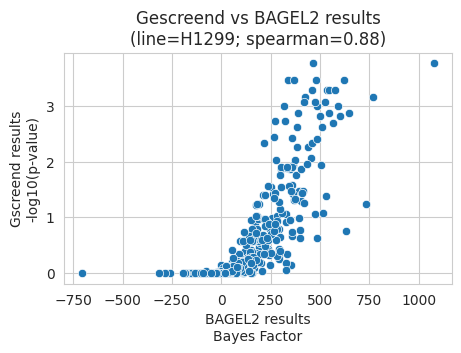

In [54]:
with sns.axes_style('whitegrid'):
    fig, ax = pl.subplots(figsize=(5,3))
total_df['score_TP6'] =-np.log10(total_df['pvalue_TP6'])
sns.scatterplot(data=total_df, x='BF', y='score_TP6')
ax.set_xlabel('BAGEL2 results\nBayes Factor')
ax.set_ylabel('Gscreend results\n-log10(p-value)')
# ax.set_xlim(-300, 300)
spearman = total_df[['BF', 'score_TP6']].corr(method='spearman').iloc[0,1]
ax.set_title(f'Gescreend vs BAGEL2 results\n(line={cell_line}; spearman=%.2f)' % spearman)
pl.show()

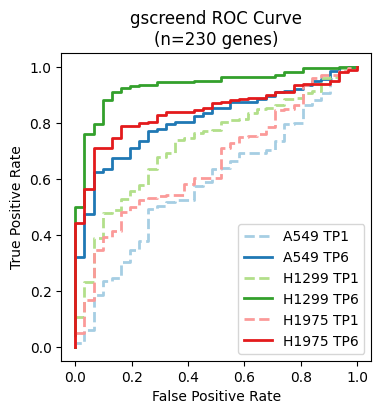

In [39]:
from sklearn.metrics import roc_curve
from matplotlib.cm import get_cmap

with sns.axes_style('whitegrid'):
    pl.figure(figsize=(4,4))
cmap = get_cmap('Paired')

i = 0
for line in ['A549', 'H1299', 'H1975']:
    for time in ['TP1', 'TP6']:
        sdf = tabs[line].set_index('Gene')
        sdf['essentiality'] = ['essential' if g in essential.index else 'non-essential' if g in non_essential.index else 'unknown' for g in sdf.index]

        mask = sdf.essentiality!='unknown'
        fpr, tpr, thresholds = roc_curve(sdf[mask].essentiality=='essential', -sdf[mask][f'LFC_{time}'])
        
        style ='--' if time=='TP1' else '-'
        color = cmap(i)
        pl.plot(fpr, tpr, label=f'{line} {time}', linewidth=2, linestyle=style, color=color)
        i += 1
pl.legend()
pl.xlabel('False Positive Rate')
pl.ylabel('True Positive Rate')
pl.title(f'gscreend ROC Curve\n(n={(sdf.essentiality!="unknown").sum()} genes)')
pl.show()


# Bagel2 (gene-wise)

In [11]:
filtered = True

name = '_filtered' if filtered else ''
# get counts
df = pd.read_table(f'../results/bagel2/pooled_screen_1_counts{name}_bagel_pr_gene.tsv', index_col=0, header=[0,1,2])
# Annotate essentiallity based on original Bagel list
df['essentiality'] = ['essential' if g in essential.index else 'non-essential' if g in non_essential.index else 'unknown' for g in df.index]

In [14]:
sdf

,BF,Recall,Precision,FDR,essentiality
Gene,,,,,
RAN,9335.479,0.005,1.000,0.000,essential
FBL,3943.980,0.005,1.000,0.000,unknown
EIF4A1,3224.351,0.005,1.000,0.000,unknown
HNRNPA1,2964.005,0.005,1.000,0.000,unknown
RPS16,2917.580,0.010,1.000,0.000,essential
...,...,...,...,...,...
BIN1,-527.879,1.000,0.865,0.135,unknown
HOTAIRM1,-555.284,1.000,0.865,0.135,unknown
PCAT1,-557.794,1.000,0.865,0.135,unknown


essential vs. non-essential: t-test independent samples, P_val:6.964e-04 t=3.438e+00


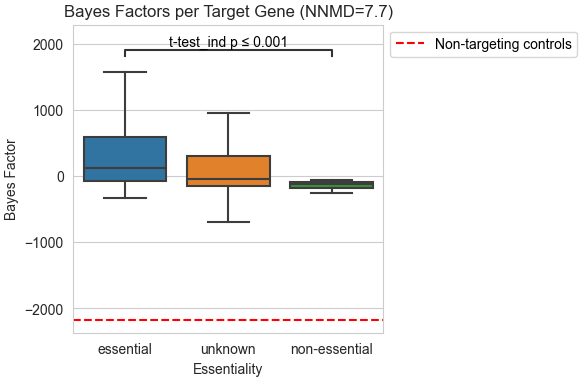

In [20]:
sdf = df.loc[:, ('alllines', 'alltimes', slice(None, None, None))]  # get all entries
# now remove the multi-index
sdf.columns = sdf.columns.droplevel([0,1])
sdf['essentiality'] = df['essentiality']

with sns.axes_style('whitegrid'):
    fig, ax = pl.subplots(1, 1, figsize=(4,4))
sns.boxplot(data=sdf, x='essentiality', y='BF', showfliers=False)
pl.axhline(sdf.loc['NT_Control', 'BF'], color='r', linestyle='--', label='Non-targeting controls')
pl.legend()
# move legend outside
pl.legend(loc='upper left', bbox_to_anchor=(1, 1))
pl.ylabel('Bayes Factor')
pl.xlabel('Essentiality')
nnmd = get_nnmd(sdf, score_column='BF')
pl.title(f'Bayes Factors per Target Gene (NNMD={np.round(nnmd,1)})', fontsize=12)

from statannotations.Annotator import Annotator
annotator = Annotator(ax, [('essential', 'non-essential')], data=sdf, x='essentiality', y='BF')
annotator.configure(test='t-test_ind', text_format='simple', loc='inside')
annotator.apply_and_annotate()

pl.savefig(f'../results/bagel2/bayes_factor_essentiality{name}.pdf', bbox_inches='tight', dpi=300)
pl.show()

In [21]:
# BF vs guide score
cts = pd.read_csv(Path(config['TEMPDIR']) / f'pooled_screen_1/pooled_screen_1_counts{name}.csv', index_col=0)

sample_names = np.sort(cts.columns[12:])
pools = ['Sym-pool-1-3', 'Sym-pool-1-1', 'Sym-pool-1-2']
pools = np.sort(pools)
sample_names_wo_pools = [x for x in sample_names if not any([p in x for p in pools])]
controls = [x for x in cts.index if 'control' in x.lower()]

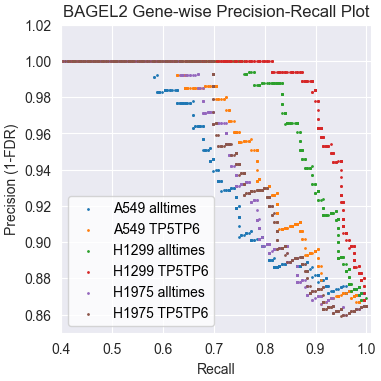

In [22]:
with sns.axes_style('darkgrid'):
    fig, ax = pl.subplots(figsize=(4,4))
selection = ['alllines', 'alltimes']
for line in ['A549', 'H1299', 'H1975']:
    for time in ['alltimes', 'TP5TP6']:
        pl.scatter(df[line, time, 'Recall'], df[line, time, 'Precision'], 
                   label=f'{line} {time}', 
                   s=1)
pl.xlim(0.4,1.01)
pl.ylim(0.85,1.02)
pl.xlabel('Recall')
pl.ylabel('Precision (1-FDR)')
pl.legend()
pl.title('BAGEL2 Gene-wise Precision-Recall Plot')
pl.savefig(f'../results/bagel2/bagel2_precision_recall{name}.pdf', bbox_inches='tight', dpi=300)
pl.show()

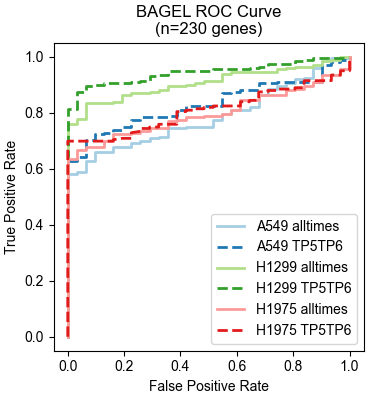

In [23]:
from sklearn.metrics import roc_curve
from matplotlib.cm import get_cmap

with sns.axes_style('whitegrid'):
    pl.figure(figsize=(4,4))
cmap = get_cmap('Paired')

i = 0
for line in ['A549', 'H1299', 'H1975']:
    for time in ['alltimes', 'TP5TP6']:
        sdf = df.loc[:, (line, time, slice(None, None, None))]  # get all entries
        # now remove the multi-index
        sdf.columns = sdf.columns.droplevel([0,1])
        sdf['essentiality'] = df['essentiality']

        mask = sdf.essentiality!='unknown'
        fpr, tpr, thresholds = roc_curve(sdf[mask].essentiality=='essential', sdf[mask].BF)
        
        style ='-' if time=='alltimes' else '--'
        color = cmap(i)
        pl.plot(fpr, tpr, label=f'{line} {time}', linewidth=2, linestyle=style, color=color)
        i += 1
pl.legend()
pl.xlabel('False Positive Rate')
pl.ylabel('True Positive Rate')
pl.title(f'BAGEL ROC Curve\n(n={(sdf.essentiality!="unknown").sum()} genes)')
pl.savefig(f'../results/bagel2/bagel2_roc{name}.pdf', bbox_inches='tight', dpi=300)
pl.show()


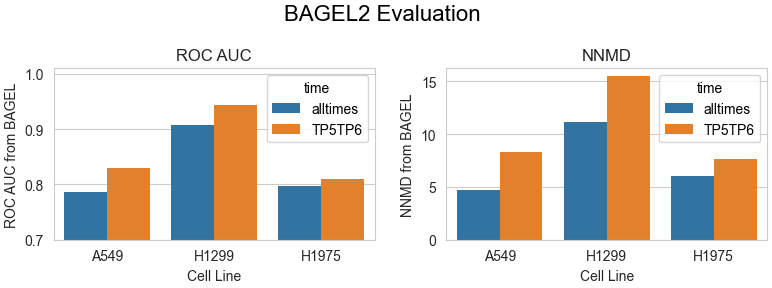

In [34]:
# AUC scores
from sklearn.metrics import roc_auc_score
aucs = {}
nnmds = {}
for line in ['A549', 'H1299', 'H1975']:
    for time in ['alltimes', 'TP5TP6']:
        sdf = df.loc[:, (line, time, slice(None, None, None))]  # get all entries
        # now remove the multi-index
        sdf.columns = sdf.columns.droplevel([0,1])
        sdf['essentiality'] = df['essentiality']

        mask = sdf.essentiality!='unknown'
        aucs[(line, time)] = roc_auc_score(sdf[mask].essentiality=='essential', sdf[mask].BF)
        nnmds[(line, time)] = get_nnmd(sdf, score_column='BF')
auc_df = pd.DataFrame(aucs, index=['AUC']).T.reset_index().rename(columns={'level_0':'line', 'level_1':'time'})
nnmd_df = pd.DataFrame(nnmds, index=['NNMD']).T.reset_index().rename(columns={'level_0':'line', 'level_1':'time'})

with sns.axes_style('whitegrid'):
    fig, axs = pl.subplots(1, 2, figsize=(4*2,3))
ax = axs[0]
sns.barplot(data=auc_df, x='line', y='AUC', hue='time', ax=ax)
ax.set_xlabel('Cell Line')
ax.set_ylabel('ROC AUC from BAGEL')
ax.set_ylim(0.7,1.01)
ax.set_title('ROC AUC')

ax = axs[1]
sns.barplot(data=nnmd_df, x='line', y='NNMD', hue='time', ax=ax)
ax.set_xlabel('Cell Line')
ax.set_ylabel('NNMD from BAGEL')
# ax.set_ylim(0.7,1.01)
ax.set_title('NNMD')

pl.suptitle('BAGEL2 Evaluation', fontsize=16)
pl.tight_layout()

pl.savefig(f'../results/bagel2/bagel2_eval{name}.pdf', bbox_inches='tight', dpi=300)
pl.show()

### Comparison with previous Cas9 data

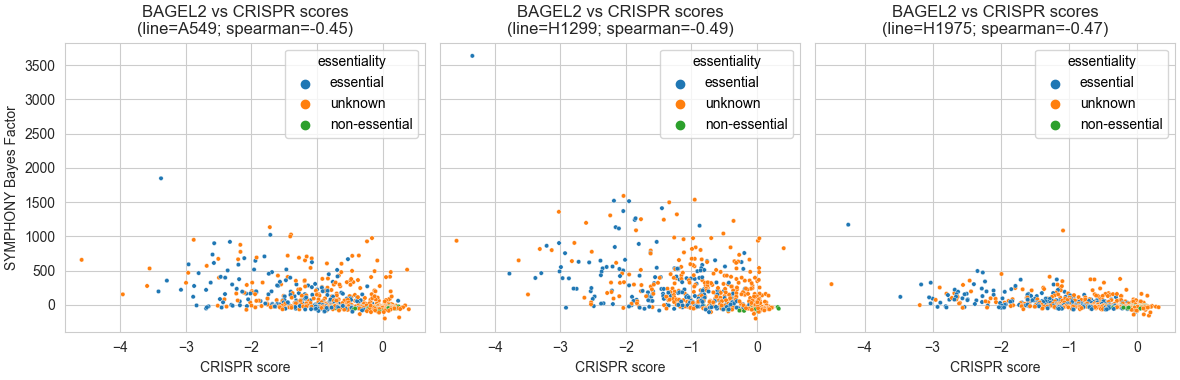

In [51]:
with sns.axes_style('whitegrid'):
    fig, axs = pl.subplots(1, 3, figsize=(4*3,4), sharey=True)
for i, line in enumerate(['A549', 'H1299', 'H1975']):
    ax = axs[i]
    sdf = df.loc[:, (line, 'TP5TP6', slice(None, None, None))]  # get all entries
    # now remove the multi-index
    sdf.columns = sdf.columns.droplevel([0,1])

    # Annotate
    sdf['essentiality'] = df['essentiality']
    sdf['guide_score'] = cts[['Guide_Score', 'Gene']].groupby('Gene').mean().loc[sdf.index, 'Guide_Score']
    gene_data = pd.read_csv('../resources/symp_101_final_gene_list.csv', index_col=0)
    sdf = pd.merge(sdf, gene_data, left_index=True, right_index=True, how='left')
    
    cl_name = f'NCI{line}' if line!='A549' else line
    sns.scatterplot(data=sdf, y='BF', x=f'{cl_name}_Crs', hue='essentiality', s=10, ax=ax)
    # add spearman correlation
    spearman = sdf[['BF', f'{cl_name}_Crs']].corr(method='spearman').iloc[0,1]
    ax.set_xlabel('CRISPR score')
    ax.set_ylabel('SYMPHONY Bayes Factor')
    ax.set_title(f'BAGEL2 vs CRISPR scores\n(line={line}; spearman=%.2f)' % spearman)
pl.tight_layout()
pl.savefig(f'../results/bagel2/bagel2_vs_crispr{name}.pdf', bbox_inches='tight', dpi=300)
pl.show()

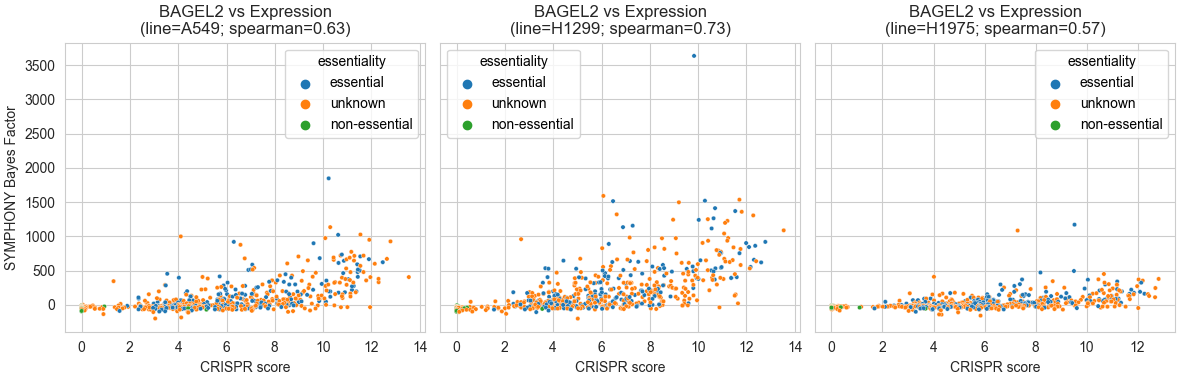

In [52]:
with sns.axes_style('whitegrid'):
    fig, axs = pl.subplots(1, 3, figsize=(4*3,4), sharey=True)
for i, line in enumerate(['A549', 'H1299', 'H1975']):
    ax = axs[i]
    sdf = df.loc[:, (line, 'TP5TP6', slice(None, None, None))]  # get all entries
    # now remove the multi-index
    sdf.columns = sdf.columns.droplevel([0,1])

    # Annotate
    sdf['essentiality'] = df['essentiality']
    sdf['guide_score'] = cts[['Guide_Score', 'Gene']].groupby('Gene').mean().loc[sdf.index, 'Guide_Score']
    gene_data = pd.read_csv('../resources/symp_101_final_gene_list.csv', index_col=0)
    sdf = pd.merge(sdf, gene_data, left_index=True, right_index=True, how='left')
    
    cl_name = f'NCI{line}' if line!='A549' else line
    sns.scatterplot(data=sdf, y='BF', x=f'{cl_name}_Exp', hue='essentiality', s=10, ax=ax)
    # add spearman correlation
    spearman = sdf[['BF', f'{cl_name}_Exp']].corr(method='spearman').iloc[0,1]
    ax.set_xlabel('CRISPR score')
    ax.set_ylabel('SYMPHONY Bayes Factor')
    ax.set_title(f'BAGEL2 vs Expression\n(line={line}; spearman=%.2f)' % spearman)
pl.tight_layout()
pl.savefig(f'../results/bagel2/bagel2_vs_depmap_expression{name}.pdf', bbox_inches='tight', dpi=300)
pl.show()

### Correlation of BFs across lines

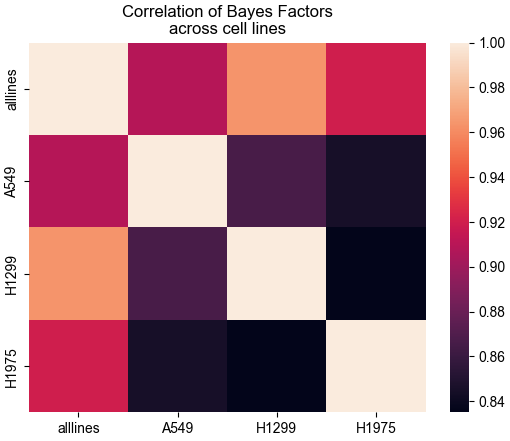

In [56]:
sdf = df.xs('BF', level=2, axis=1).xs('alltimes', level=1, axis=1)
sns.heatmap(sdf.corr())
pl.title('Correlation of Bayes Factors\nacross cell lines')
pl.savefig(f'../results/bagel2/bagel2_line_correlation{name}.pdf', bbox_inches='tight', dpi=300)
pl.show()

# MAGeCK

## Guide Ranking, Filtering

- Look for highest MAGeCK score and absLFC across cell lines
- Set threshold for filtering to XXth percentile of max score in NT guides
- Mark all guides with less score than threshold as "filtered out"

In [6]:
all_guide_rankings = pd.concat({cell_line: pd.read_csv(f'../results/mageck/summaries/{cell_line}/gene_pooled_screen_1_counts_mageck.sgrna_summary.txt', sep='\t', index_col=0) for cell_line in cell_line_dict.values()}, axis=1)
# aggregate
all_guide_rankings[('summary', 'max_score')] = all_guide_rankings.loc[:, (slice(None), 'score')].max(axis=1)
all_guide_rankings[('summary', 'mean_score')] = all_guide_rankings.loc[:, (slice(None), 'score')].mean(axis=1)
all_guide_rankings[('summary', 'min_score')] = all_guide_rankings.loc[:, (slice(None), 'score')].min(axis=1)
all_guide_rankings[('summary', 'max_LFC')] = all_guide_rankings.loc[:, (slice(None), 'LFC')].max(axis=1)
all_guide_rankings[('summary', 'mean_LFC')] = all_guide_rankings.loc[:, (slice(None), 'LFC')].mean(axis=1)
all_guide_rankings[('summary', 'min_LFC')] = all_guide_rankings.loc[:, (slice(None), 'LFC')].min(axis=1)
all_guide_rankings[('summary', 'absmax_LFC')] = np.abs(all_guide_rankings.loc[:, (slice(None), 'LFC')]).max(axis=1)
all_guide_rankings[('summary', 'is_control')] = all_guide_rankings.index.str.contains('Control').astype(str)

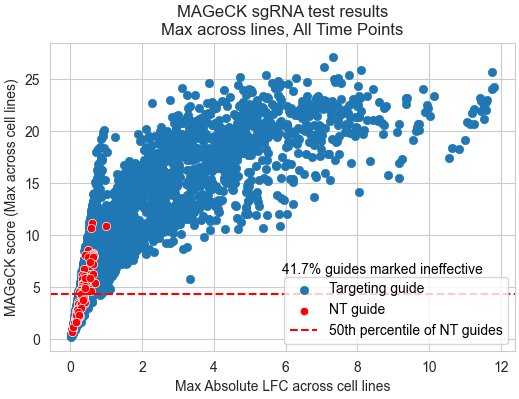

In [8]:
data = all_guide_rankings.loc[:, 'summary']
data_control = data[(data.is_control=='True')]

y_key = 'max_score'
p = 50

with sns.axes_style('whitegrid'):
    fig, ax = pl.subplots(figsize=(6,4))

sns.scatterplot(data=data, x='absmax_LFC', y=y_key, edgecolor=None, label='Targeting guide')
sns.scatterplot(data=data_control, x='absmax_LFC', y=y_key, color='red', label='NT guide')

tresh = np.percentile(data_control[y_key], p)
pl.axhline(tresh, color='r', linestyle='--', label=f'{p}th percentile of NT guides')
percent_removed = ((data[y_key]<tresh) & (data.is_control=='False')).mean()
pl.text(0.5, 0.25, f'{percent_removed:.1%} guides marked ineffective', transform=pl.gca().transAxes)
pl.title('MAGeCK sgRNA test results\nMax across lines, All Time Points')
pl.ylabel('MAGeCK score (Max across cell lines)')
pl.xlabel('Max Absolute LFC across cell lines')
pl.legend()
pl.show()

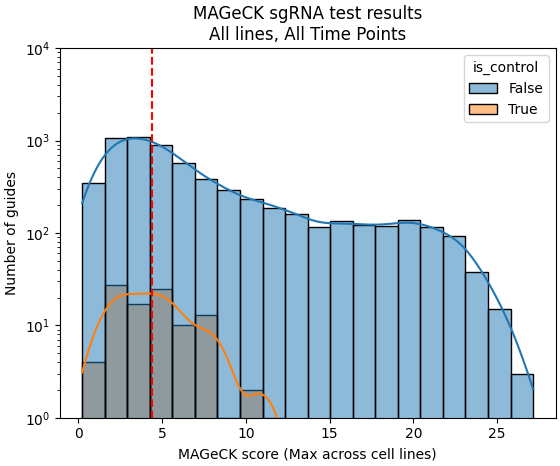

In [5]:
sns.histplot(data=data, x='max_score', bins=20, kde=True, hue='is_control')
pl.axvline(tresh, color='r', linestyle='--', label=f'{p}th percentile of controls')
pl.yscale('log')
pl.ylim(1, 1e4)
pl.ylabel('Number of guides')
pl.xlabel('MAGeCK score (Max across cell lines)')
pl.title('MAGeCK sgRNA test results\nAll lines, All Time Points')
pl.show()

In [6]:
# annotate
all_guide_rankings[('summary', 'is_working')] = all_guide_rankings.loc[:, 'summary'].max_score>tresh

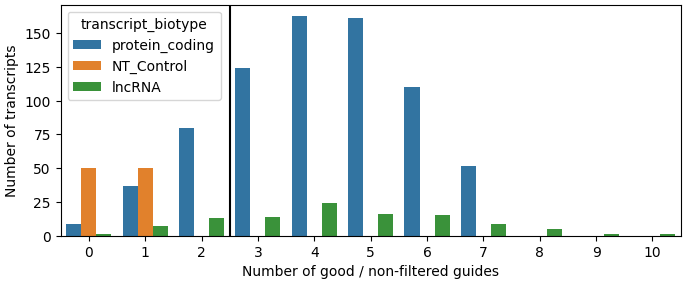

In [90]:
# How many guides are marked per target?
data = all_guide_rankings.loc[:, 'summary']
# add infos
df = pd.read_csv(Path(config['TEMPDIR']) / 'pooled_screen_1/pooled_screen_1_counts.csv', index_col=0)
for col in ['Gene', 'Transcript_ID', 'transcript_biotype', 'Region']:
    data[col] = df.loc[data.index, col]
# counting
sdf = data.groupby(['Transcript_ID', 'transcript_biotype'], observed=False).sum().is_working.reset_index()
sdf = sdf[(sdf.transcript_biotype.isin(['protein_coding', 'lncRNA', 'NT_Control']))]
sdf.rename(columns={'is_working':'good_guides_count'}, inplace=True)

pl.figure(figsize=(8,3))
sns.barplot(data=sdf.value_counts(['transcript_biotype', 'good_guides_count']).reset_index(),
            x='good_guides_count', y=0, hue='transcript_biotype')
pl.xlabel('Number of good / non-filtered guides')
pl.ylabel('Number of transcripts')
pl.axvline(2.5, color='k')
pl.show()

In [93]:
# filtering would remove too many guides for these target, so we enforce keeping at least 3 guides
N = 3
key = 'keep_flag'
too_few = sdf.loc[sdf.good_guides_count<N, 'Transcript_ID']
print(len(too_few))

data = all_guide_rankings.loc[:, 'summary']
# add infos
df = pd.read_csv(Path(config['TEMPDIR']) / 'pooled_screen_1/pooled_screen_1_counts.csv', index_col=0)
for col in ['Gene', 'Transcript_ID', 'transcript_biotype', 'Region']:
    data[col] = df.loc[data.index, col]
keep = data[data.Transcript_ID.isin(too_few)].groupby('Transcript_ID').max_score.nlargest(N).index.get_level_values(1)
all_guide_rankings.loc[:, ('summary', key)] = all_guide_rankings.loc[:, ('summary', 'is_working')].copy()
all_guide_rankings.loc[df.loc[all_guide_rankings.index].Transcript_ID.isin(too_few), ('summary', key)] = False
all_guide_rankings.loc[keep, ('summary', key)] = True

247


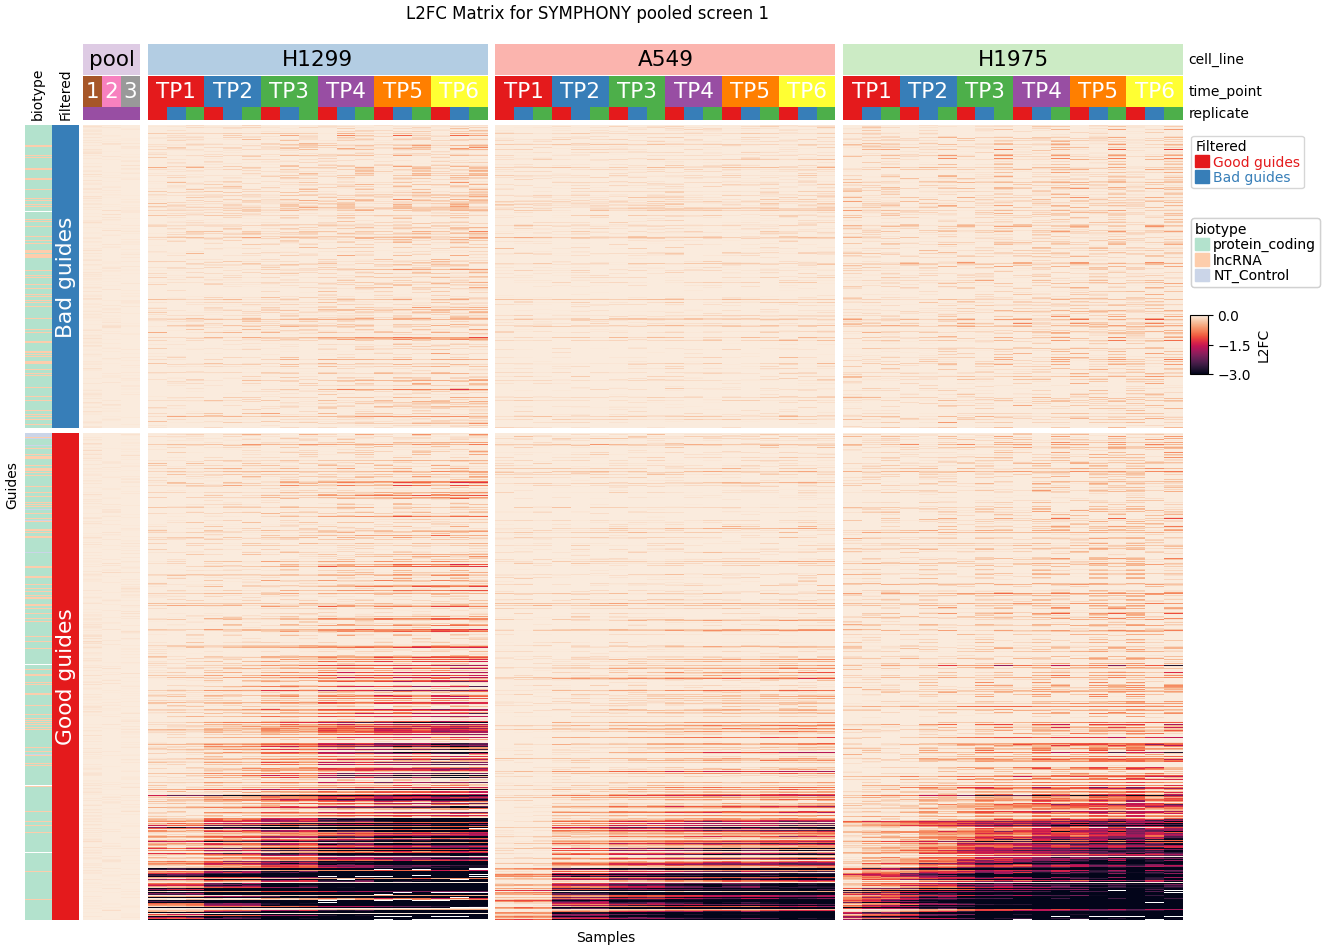

In [95]:
# visualize in heatmap
df = pd.read_csv(Path(config['TEMPDIR']) / 'pooled_screen_1/pooled_screen_1_counts.csv', index_col=0)

sample_names = np.sort(df.columns[12:])
pools = ['Sym-pool-1-3', 'Sym-pool-1-1', 'Sym-pool-1-2']
pools = np.sort(pools)
sample_names_wo_pools = [x for x in sample_names if not any([p in x for p in pools])]
controls = [x for x in df.index if 'control' in x.lower()]

# First I normalize for seq-depth by bringing all NT guides to the same count
target = df.loc[controls, sample_names_wo_pools].mean().mean()  # mean of NTs in control
ist = df.loc[controls, sample_names].mean()  # mean of NTs in all
norm_factor = target / ist  # make all NT mean counts equal to those in control
ndf = df.loc[:, sample_names] * norm_factor  # normalize

# Foldchange to Pool after seq-depth normalization based on NT depth
fc = (ndf.loc[:, sample_names].T / ndf.loc[:, pools].mean(axis=1)).T  # normalize to control (pools)
l2fc = np.log2(fc)
l2fc[l2fc==-np.infty] = None

import PyComplexHeatmap as pch
df['mean_l2fc'] = l2fc.mean(axis=1)
biotype = df.sort_values(['transcript_biotype', 'mean_l2fc']).transcript_biotype
biotype = biotype[~biotype.isin(['protein_coding_CDS_not_defined', 'retained_intron'])]
is_working = all_guide_rankings.loc[:, 'summary'].loc[data.index].sort_values(by=[key, 'max_score'])[key].astype(str).map({'True': 'Good guides', 'False': 'Bad guides'})

cell_line_dict_ = {f'0{x}': y for x, y in cell_line_dict.items()}
cell_line = pd.Series({x: x.split('-')[1] for x in sample_names}).replace(cell_line_dict_)
replicate = pd.Series({x: x.split('-')[2] for x in sample_names})
time_point = pd.Series({x: x.split('-')[3].split('_')[0] for x in sample_names})
col_order = pd.concat([cell_line, replicate, time_point], axis=1).sort_values([0, 2, 1]).index  # sort by time before replicate

# select and reorder
data = l2fc.loc[:, col_order]

top_ha = pch.HeatmapAnnotation(
    cell_line=pch.anno_simple(cell_line.loc[col_order], add_text=True, height=7, cmap='Pastel1'),
    time_point=pch.anno_simple(time_point.loc[col_order], add_text=True, height=7, cmap='Set1'),
    replicate=pch.anno_simple(replicate.loc[col_order], add_text=False),
    verbose=0, axis=1, plot_legend=False
)

left_ha = pch.HeatmapAnnotation(
    biotype=pch.anno_simple(biotype, legend=True, height=7, add_text=False, cmap='Pastel2'),
    Filtered=pch.anno_simple(is_working, legend=True, height=7, add_text=True, cmap='Set1'),
    verbose=0, axis=0, plot_legend=True
)

pl.figure(figsize=(15, 10))
cm = pch.ClusterMapPlotter(
    data=data, 
    left_annotation=left_ha, top_annotation=top_ha,
    row_cluster=False, col_cluster=False,
    row_split=is_working,
    col_split=cell_line.loc[col_order],
    col_split_gap=2, row_split_gap=1,
    label='beta', row_dendrogram=False, col_dendrogram=False,
    legend_gap=7, rasterized=True, cmap='rocket', vmin=-3, vmax=0,
    legend_kws=dict(label='L2FC'),
    xlabel="Samples", ylabel='Guides', legend_hpad=0,
    verbose=0
)
pl.suptitle('L2FC Matrix for SYMPHONY pooled screen 1', y=0.92)
# pl.savefig('../results/figures/count_matrix_l2fc_heatmap_simple.png', dpi=300)
# pl.savefig('../results/figures/count_matrix_l2fc_heatmap_simple.pdf', dpi=300)
pl.show()

In [96]:
# save results
# save results
all_guide_rankings.to_csv('../results/tables/pooled_screen_1_mageck_filtered_guides_v2.tsv', sep='\t')

## Gene Ranking

In [5]:
# The gene ranking results
filtered = True
name = '_filtered' if filtered else ''
gene_ranking = pd.read_csv(f'../results/mageck/alllines/gene_pooled_screen_1_counts{name}_mageck.gene_summary.txt', sep='\t', index_col=0)
gene_ranking = gene_ranking.reset_index().set_index(['id', 'num'])
gene_ranking.columns = pd.MultiIndex.from_arrays([
    [x.split('_vs_')[0] for x in gene_ranking.columns],
    [x.split('|')[1] for x in gene_ranking.columns],
    [x.split('|')[2] for x in gene_ranking.columns]
])

# For each sample, there are results for both pos and neg enrichment tests
# Result statistics include score, p-value, fdr, rank, "goodsgrna??", lfc
gene_ranking.head()

sym-01-01-TP6                                                      \
                     neg                                                 pos   
                   score   p-value       fdr rank goodsgrna     lfc    score   
id     num                                                                     
RAN    20   1.488200e-10  0.000005  0.000036    1        19 -4.9633  0.99998   
FBL    12   5.304500e-09  0.000005  0.000036    2        12 -6.6671  1.00000   
TMSB4X 7    9.309300e-08  0.000005  0.000036    3         7 -3.6477  1.00000   
SNHG16 10   3.598900e-07  0.000005  0.000036    4        10 -3.3369  1.00000   
EIF4A1 7    7.761900e-07  0.000005  0.000036    5         7 -4.4816  0.99999   

                              ... sym-03-03-TP6                         \
                              ...           neg                          
           p-value  fdr rank  ...           fdr rank goodsgrna     lfc   
id     num                    ...                                        
RAN    20      1.0  1.0  724  ...      0.000053    1        19 -2.3943   
FBL    12      1.0  1.0  733  ...      0.000134   25        10 -1.2671   
TMSB4X 7       1.0  1.0  732  ...      0.000053    6         7 -2.2624   
SNHG16 10      1.0  1.0  731  ...      0.000053    2        10 -2.1123   
EIF4A1 7       1.0  1.0  728  ...      0.000053    4         7 -3.9778   

                                                          
                pos                                       
              score  p-value  fdr rank goodsgrna     lfc  
id     num                                                
RAN    20   0.99972  0.99988  1.0  719         1 -2.3943  
FBL    12   0.32308  0.60271  1.0  358         2 -1.2671  
TMSB4X 7    0.99999  1.00000  1.0  732         0 -2.2624  
SNHG16 10   0.99998  1.00000  1.0  729         0 -2.1123  
EIF4A1 7    1.00000  1.00000  1.0  733         0 -3.9778  

[5 rows x 108 columns]

<Axes: ylabel='id-num'>

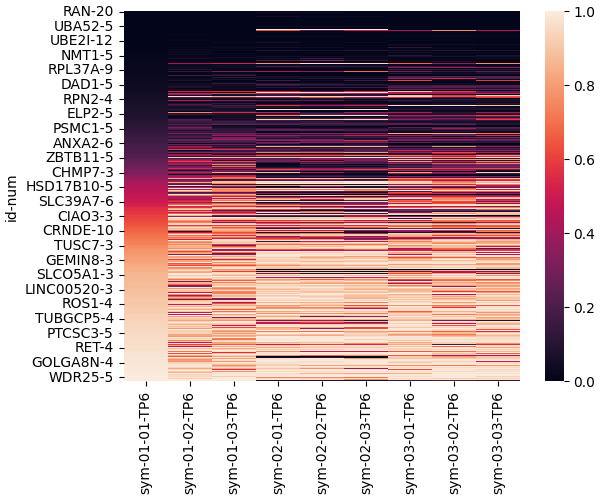

In [6]:
sns.heatmap(gene_ranking.T.loc[:, 'neg', 'score'].T)

<Axes: xlabel='lfc', ylabel='score'>

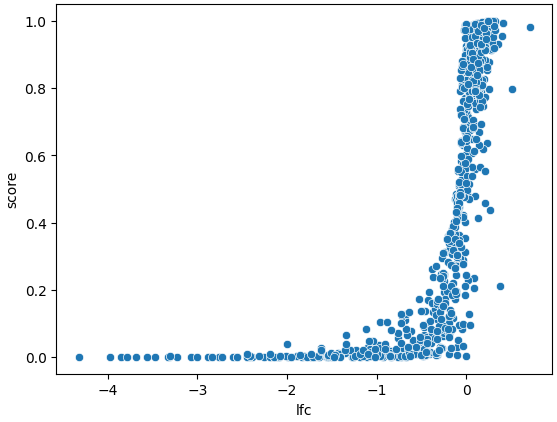

In [7]:
sns.scatterplot(data=gene_ranking.T.loc['sym-03-03-TP6', 'neg', :].T, x='lfc', y='score')

In [8]:
# unfiltered:
filtered = False
name = '_filtered' if filtered else ''
gene_ranking_ = pd.read_csv(f'../results/mageck/alllines/gene_pooled_screen_1_counts{name}_mageck.gene_summary.txt', sep='\t', index_col=0)
gene_ranking_ = gene_ranking_.reset_index().set_index(['id', 'num'])
gene_ranking_.columns = pd.MultiIndex.from_arrays([
    [x.split('_vs_')[0] for x in gene_ranking_.columns],
    [x.split('|')[1] for x in gene_ranking_.columns],
    [x.split('|')[2] for x in gene_ranking_.columns]
])

In [9]:
df_ = gene_ranking_.loc[:, (slice(None), 'neg', 'score')].mean(1).to_frame().rename(columns={0: 'MAGeCK_score'})
df_.index = df_.index.droplevel(1)
df = gene_ranking.loc[:, (slice(None), 'neg', 'score')].mean(1).to_frame().rename(columns={0: 'MAGeCK_score'})
df.index = df.index.droplevel(1)

In [10]:
tab = pd.merge(df, df_, left_index=True, right_index=True, suffixes=('_filtered', '_unfiltered'), how='outer')

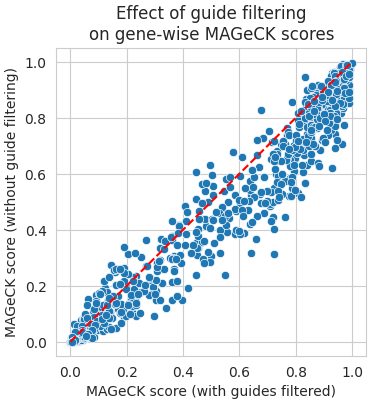

In [11]:
with sns.axes_style('whitegrid'):
    fig, ax = pl.subplots(figsize=(4,4))
sns.scatterplot(data=tab.fillna(0), x='MAGeCK_score_filtered', y='MAGeCK_score_unfiltered')
pl.xlabel('MAGeCK score (with guides filtered)')
pl.ylabel('MAGeCK score (without guide filtering)')
pl.title('Effect of guide filtering\non gene-wise MAGeCK scores')
pl.plot([0, 1], [0, 1], color='r', linestyle='--')
pl.show()

## Transcript ranking

In [91]:
# The gene ranking results
filtered = True
name = '_filtered' if filtered else ''
gene_ranking = pd.read_csv(f'../results/mageck/alllines/transcript_pooled_screen_1_counts{name}_mageck.gene_summary.txt', sep='\t', index_col=0)
gene_ranking = gene_ranking.reset_index().set_index(['id', 'num'])
gene_ranking.columns = pd.MultiIndex.from_arrays([
    [x.split('_vs_')[0] for x in gene_ranking.columns],
    [x.split('|')[1] for x in gene_ranking.columns],
    [x.split('|')[2] for x in gene_ranking.columns]
])

# For each sample, there are results for both pos and neg enrichment tests
# Result statistics include score, p-value, fdr, rank, "goodsgrna??", lfc
gene_ranking.head()

sym-01-01-TP6                                             \
                              neg                                              
                            score   p-value       fdr rank goodsgrna     lfc   
id              num                                                            
ENST00000451311 7        0.000029  0.000005  0.000007    1         7 -3.8822   
ENST00000293831 7        0.000095  0.000005  0.000007    2         7 -4.7127   
ENST00000579618 6        0.000138  0.000005  0.000007    3         5 -4.0365   
ENST00000230050 5        0.000202  0.000005  0.000007    4         5 -4.8973   
ENST00000251453 6        0.000333  0.000005  0.000007    5         6 -6.2830   

                                                  ... sym-03-03-TP6       \
                          pos                     ...           neg        
                        score  p-value  fdr rank  ...           fdr rank   
id              num                               ...                      
ENST00000451311 7    0.999970  1.00000  1.0  640  ...      0.000007   10   
ENST00000293831 7    0.998840  1.00000  1.0  632  ...      0.000007    2   
ENST00000579618 6    0.078182  0.40137  1.0   90  ...      0.000007   43   
ENST00000230050 5    0.999800  1.00000  1.0  639  ...      0.000007    4   
ENST00000251453 6    0.999050  1.00000  1.0  636  ...      0.000007   26   

                                                                             \
                                           pos                                
                    goodsgrna     lfc    score  p-value  fdr rank goodsgrna   
id              num                                                           
ENST00000451311 7           7 -2.6592  0.99911  1.00000  1.0  634         0   
ENST00000293831 7           7 -4.3895  0.99966  1.00000  1.0  636         0   
ENST00000579618 6           4 -2.0059  0.50398  0.99995  1.0  326         0   
ENST00000230050 5           5 -4.7399  0.99968  1.00000  1.0  638         0   
ENST00000251453 6           6 -3.7407  0.99489  1.00000  1.0  620         0   

                             
                             
                        lfc  
id              num          
ENST00000451311 7   -2.6592  
ENST00000293831 7   -4.3895  
ENST00000579618 6   -2.0059  
ENST00000230050 5   -4.7399  
ENST00000251453 6   -3.7407  

[5 rows x 108 columns]

<Axes: ylabel='id-num'>

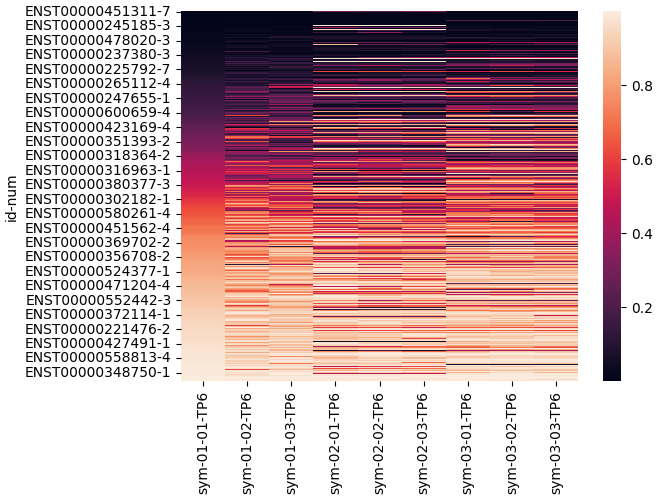

In [92]:
sns.heatmap(gene_ranking.T.loc[:, 'neg', 'score'].T)

<Axes: xlabel='lfc', ylabel='score'>

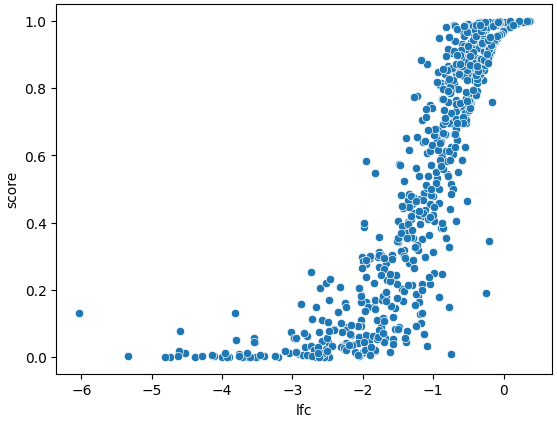

In [93]:
sns.scatterplot(data=gene_ranking.T.loc['sym-03-03-TP6', 'neg', :].T, x='lfc', y='score')